FileNotFoundError: [Errno 2] No such file or directory: 'students.csv'

In [14]:
pip install seaborn


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
pip install matplotlib


  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl (7.3 MB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/7 [pyparsing]
   -


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("student.csv")

print("First Five Rows:")
print(df.head())


print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)


print("\nData Types:")
print(df.dtypes)


print("\nMissing Values:")
print(df.isnull().sum())

First Five Rows:
    Name  Maths_Score  Science_Score Attendance_Percent    Club
0   Arun           85             90                 95  Sports
1   Asha           92             88                 98   Music
2    Ben           65             70                 75  Sports
3  Rahul           78             82                 85   Dance
4    Anu           95             96                 99   Music

Dataset Shape:
(10, 5)

Column Names:
Index(['Name', 'Maths_Score', 'Science_Score', 'Attendance_Percent', 'Club'],
      dtype='str')

Data Types:
Name                    str
Maths_Score           int64
Science_Score         int64
Attendance_Percent      str
Club                    str
dtype: object

Missing Values:
Name                  0
Maths_Score           0
Science_Score         0
Attendance_Percent    0
Club                  1
dtype: int64


In [13]:
print(df.info)

<bound method DataFrame.info of     Name  Maths_Score  Science_Score Attendance_Percent    Club
0   Arun           85             90                 95  Sports
1   Asha           92             88                 98   Music
2    Ben           65             70                 75  Sports
3  Rahul           78             82                 85   Dance
4    Anu           95             96                 99   Music
5   John           60             65             Sports     NaN
6  Priya           88             91                 92   Dance
7   Ravi           72             68                 80   Music
8  Meera           60             65                 70  Sports
9  Kiran           80             85                 90   Dance>


In [14]:
maths = df["Maths_Score"].dropna().to_numpy() 
science =df["Science_Score"].dropna().to_numpy()
print("MathsMeans:",np.mean(maths)) 
print("Maths Minimum",np.min(maths))
print("Maths Maximum",np.max(maths))

print("science mean",np.mean(science))
print("science Minimum",np.min(science))
print("Scienceminimum",np.max(science))

MathsMeans: 77.5
Maths Minimum 60
Maths Maximum 95
science mean 80.0
science Minimum 65
Scienceminimum 96


In [19]:
print("summary statics:")
print(df.describe())
sorted_df=df.sort_values(
    by="Maths_Score",
    ascending=False
)
print("top five student")
print(sorted_df.head())

summary statics:
       Maths_Score  Science_Score
count    10.000000      10.000000
mean     77.500000      80.000000
std      12.860361      11.850926
min      60.000000      65.000000
25%      66.750000      68.500000
50%      79.000000      83.500000
75%      87.250000      89.500000
max      95.000000      96.000000
top five student
    Name  Maths_Score  Science_Score Attendance_Percent    Club
4    Anu           95             96                 99   Music
1   Asha           92             88                 98   Music
6  Priya           88             91                 92   Dance
0   Arun           85             90                 95  Sports
9  Kiran           80             85                 90   Dance


In [21]:
print("duplicate row")
print(df.duplicated().sum())
df=df.drop_duplicates()
print(df.shape)

duplicate row
0
(10, 5)


In [26]:
import pandas as pd
import numpy as np

print(df.isnull().sum())

numerical_columns = df.select_dtypes(
    include=np.number
).columns

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())


categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])


print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Name                  0
Maths_Score           0
Science_Score         0
Attendance_Percent    0
Club                  1
dtype: int64

Missing Values After Cleaning:
Name                  0
Maths_Score           0
Science_Score         0
Attendance_Percent    0
Club                  0
dtype: int64


C:\Users\VICTUS\AppData\Local\Temp\ipykernel_27480\500566727.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [20]:
print("Categorical Columns:")
print(df.select_dtypes(include="object").columns)


encoded_df = pd.get_dummies(
    df,
    columns=["Club"],
    dtype=int
)

print("\nEncoded Dataset:")
print(encoded_df.head())

Categorical Columns:
Index(['Name', 'Attendance_Percent', 'Club'], dtype='str')

Encoded Dataset:
    Name  Maths_Score  Science_Score Attendance_Percent  Club_Dance  \
0   Arun           85             90                 95           0   
1   Asha           92             88                 98           0   
2    Ben           65             70                 75           0   
3  Rahul           78             82                 85           1   
4    Anu           95             96                 99           0   

   Club_Music  Club_Sports  
0           0            1  
1           1            0  
2           0            1  
3           0            0  
4           1            0  


C:\Users\VICTUS\AppData\Local\Temp\ipykernel_27480\3131530117.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include="object").columns)


In [21]:
Q1 = df["Maths_Score"].quantile(0.25)

Q3 = df["Maths_Score"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Maths_Score"] < lower_limit) |
    (df["Maths_Score"] > upper_limit)
]

print("Outliers:")
print(outliers)

print("Number of Outliers:", len(outliers))

Outliers:
Empty DataFrame
Columns: [Name, Maths_Score, Science_Score, Attendance_Percent, Club]
Index: []
Number of Outliers: 0


In [9]:

target = "Maths_Score"


features = [
    "Science_Score",
    "Attendance_Percent",
    "Club"
]

X = df[features]

y = df[target]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Science_Score Attendance_Percent    Club
0             90                 95  Sports
1             88                 98   Music
2             70                 75  Sports
3             82                 85   Dance
4             96                 99   Music

Target:
0    85
1    92
2    65
3    78
4    95
Name: Maths_Score, dtype: int64


In [ ]:

print("Maths Median:")
print(df["Maths_Score"].median())


print("\nMaths Mode:")
print(df["Maths_Score"].mode())

print("\nMaths Variance:")
print(df["Maths_Score"].var())

print("\nMaths Standard Deviation:")
print(df["Maths_Score"].std())

Maths Median:
79.0

Maths Mode:
0    60
Name: Maths_Score, dtype: int64

Maths Variance:
165.38888888888889

Maths Standard Deviation:
12.860361149240285


In [8]:
correlation = df[
    ["Maths_Score", "Science_Score", "Attendance_Percent"]
]

print("Correlation:")
print(correlation)

Correlation:
   Maths_Score  Science_Score Attendance_Percent
0           85             90                 95
1           92             88                 98
2           65             70                 75
3           78             82                 85
4           95             96                 99
5           60             65             Sports
6           88             91                 92
7           72             68                 80
8           60             65                 70
9           80             85                 90


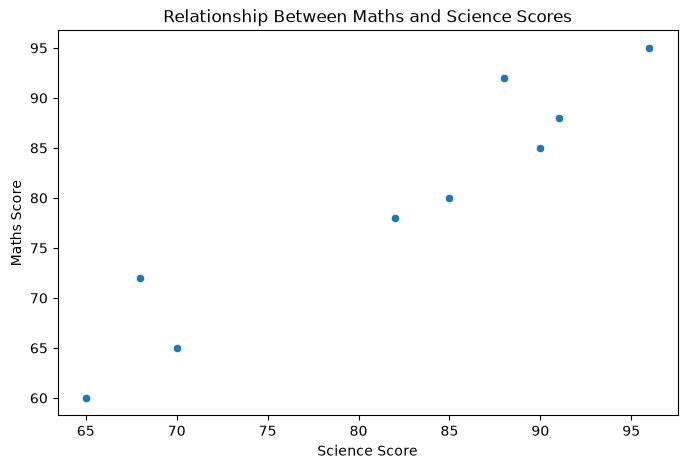

In [29]:




plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Science_Score",
    y="Maths_Score"
)

plt.title("Relationship Between Maths and Science Scores")

plt.xlabel("Science Score")

plt.ylabel("Maths Score")

plt.show()